# Phase B.1 – IoU Head Recalibration
##Motivation
Notebook 03 showed that the IoU Prediction Head of SAM2 is poorly calibrated on Sentinel‑2 imagery.

Observed evidence:

* Predicted IoU mean ≈ 0.96
* True IoU mean ≈ 0.80
* Correlation ≈ -0.0087

Therefore, we investigate whether a lightweight calibration model can learn a mapping between predicted IoU and measured IoU on agricultural parcels.

This experiment does not modify the SAM2 architecture. Its purpose is to determine whether useful information already exists in the decoder outputs.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd

import torch
import torch.nn as nn

import matplotlib.pyplot as plt

from PIL import Image

Configuracion

In [2]:
DEVICE = (
    "cuda"
    if torch.cuda.is_available()
    else "cpu"
)

print(DEVICE)

cpu


Cargar drive

In [3]:
from google.colab import drive

drive.mount('/content/drive')

DATA_ROOT = Path(
    "/content/drive/MyDrive/Sen4SAM"
)

Mounted at /content/drive


Recuperar dataset de entrenamiento

In [5]:
df = pd.read_csv(
    DATA_ROOT / "decoder_dataset.csv"
)

df.head()

,pred_iou,true_iou,area
0,0.973092,0.859712,527
1,0.971395,0.490114,3844
2,0.971328,0.927867,2789
3,0.969840,0.501642,2105
4,0.968559,0.853383,256


In [6]:
print(df.shape)

df.describe()

(30, 3)


,pred_iou,true_iou,area
count,30.000000,30.000000,30.000000
mean,0.960208,0.798250,1748.766667
std,0.006792,0.192365,1344.092482
min,0.949514,0.355222,256.000000
25%,0.956115,0.721443,905.750000
50%,0.959178,0.897895,1310.000000
75%,0.965795,0.933086,2363.250000
max,0.973092,0.948737,6999.000000


Correlación inicial

In [7]:
corr = df["pred_iou"].corr(
    df["true_iou"]
)

print(
    f"Baseline correlation = {corr:.4f}"
)

Baseline correlation = -0.0087


# Construcción del dataset PyTorch

Entradas

In [8]:
X = torch.tensor(
    df["pred_iou"].values,
    dtype=torch.float32
).reshape(-1,1)

Salidas

In [10]:
Y = torch.tensor(
    df["true_iou"].values,
    dtype=torch.float32
).reshape(-1,1)

Verificar

In [11]:
print(X.shape)

print(Y.shape)

torch.Size([30, 1])
torch.Size([30, 1])


Split train / validation

In [12]:
n = len(X)

idx = int(
    0.8 * n
)

X_train = X[:idx]
Y_train = Y[:idx]

X_val = X[idx:]
Y_val = Y[idx:]

Modelo de recalibración

In [13]:
calibrator = nn.Sequential(

    nn.Linear(1,16),

    nn.ReLU(),

    nn.Linear(16,16),

    nn.ReLU(),

    nn.Linear(16,1)

).to(DEVICE)

Loss y optimizador

In [14]:
criterion = nn.MSELoss()
optimizer = torch.optim.Adam(
    calibrator.parameters(),
    lr=1e-3
)

Entrenamiento

In [15]:
train_losses = []
val_losses = []

EPOCHS = 200

for epoch in range(EPOCHS):

    calibrator.train()

    pred = calibrator(
        X_train.to(DEVICE)
    )

    loss = criterion(
        pred,
        Y_train.to(DEVICE)
    )

    optimizer.zero_grad()

    loss.backward()

    optimizer.step()

    train_losses.append(
        loss.item()
    )

    calibrator.eval()

    with torch.no_grad():

        pred_val = calibrator(
            X_val.to(DEVICE)
        )

        val_loss = criterion(
            pred_val,
            Y_val.to(DEVICE)
        )

        val_losses.append(
            val_loss.item()
        )

    if epoch % 20 == 0:

        print(
            epoch,
            loss.item(),
            val_loss.item()
        )

0 0.3873983919620514 0.28595927357673645
20 0.24490301311016083 0.17338967323303223
40 0.1409997195005417 0.0984821617603302
60 0.07404755055904388 0.05844734236598015
80 0.03889589384198189 0.048536267131567
100 0.030657807365059853 0.05781276524066925
120 0.030744576826691628 0.060528408735990524
140 0.030627941712737083 0.058304864913225174
160 0.030629627406597137 0.058128055185079575
180 0.030627816915512085 0.058415740728378296


Curva de aprendizaje

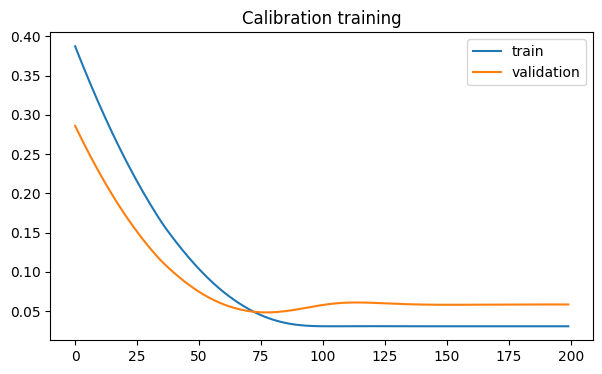

In [16]:
plt.figure(figsize=(7,4))

plt.plot(
    train_losses,
    label="train"
)

plt.plot(
    val_losses,
    label="validation"
)

plt.legend()

plt.title(
    "Calibration training"
)

plt.show()

Evaluación

In [17]:
with torch.no_grad():

    calibrated = calibrator(
        X.to(DEVICE)
    ).cpu().numpy().flatten()

Crear dataframe

In [18]:
results = df.copy()

results["calibrated_iou"] = calibrated

## Comparar correlaciones

Antes

In [19]:
corr_before = results["pred_iou"].corr(
    results["true_iou"]
)

Despues

In [20]:
corr_after = results["calibrated_iou"].corr(
    results["true_iou"]
)

In [21]:
print(
    "Before:",
    corr_before
)

print(
    "After:",
    corr_after
)

Before: -0.008693873806917506
After: -0.008695110202531966


Figura final

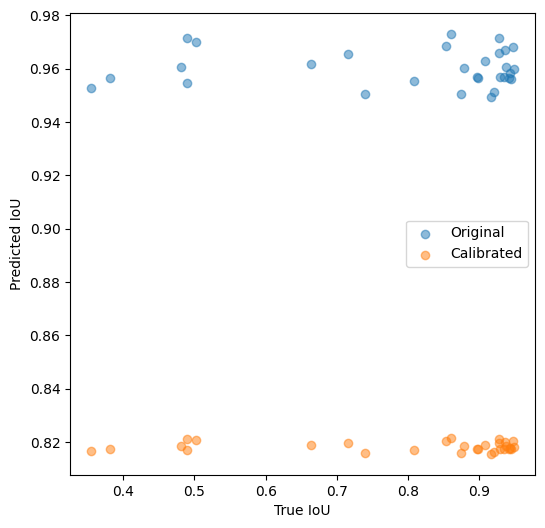

In [22]:
plt.figure(figsize=(6,6))

plt.scatter(
    results["true_iou"],
    results["pred_iou"],
    alpha=0.5,
    label="Original"
)

plt.scatter(
    results["true_iou"],
    results["calibrated_iou"],
    alpha=0.5,
    label="Calibrated"
)

plt.legend()

plt.xlabel(
    "True IoU"
)

plt.ylabel(
    "Predicted IoU"
)

plt.show()

# Resultados
A simple post-hoc calibration model was unable to improve the relationship between predicted IoU and true IoU.

Observed correlations:

* Original prediction: -0.0087
* Calibrated prediction: -0.0087

This suggests that the decoder's IoU estimate itself does not contain sufficient information to explain the real quality of agricultural parcel masks.

Therefore, future adaptation should target the internal decoder representations rather than performing post-hoc score calibration.